In [1]:
import pandas as pd

df = pd.read_csv('sales_data.csv')

dates = ['order_date','shipping_date','delivery_date']
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

In [2]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [3]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [4]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]

df.to_csv("sales_clean.csv", index=False)

date_error_count = (df['date_error']).sum()

print(date_error_count,'건,',df.shape)


147 건, (1004, 15)


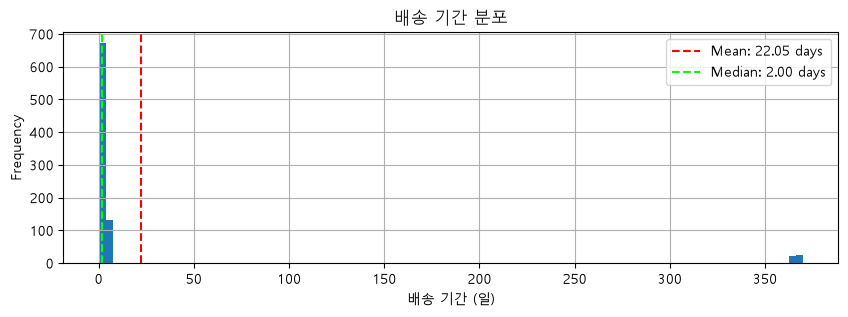

배송기간 분포의 350일 근처에 갯수는 적으나 값이 큰 덩어리들이 평균을 끌어올림.
저 덩어리들은 에러 값으로 보고 행 자체를 배제하는 것이 좋아 보임. 물리적으로 불가능한 수치는 아니나, 정상값들과 덩어리 사이에 가우시안 분포처럼 값들이 없으므로 에러라고 보는 게 적합함.


In [5]:
import matplotlib.pyplot as plt 
import platform

fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

valid_dates_df = df[~df['date_error']]

delivery_duration = (valid_dates_df['delivery_date'] -  valid_dates_df['shipping_date']).dt.days

delivery_duration.hist(bins=100,figsize=(10,3) )


mean = delivery_duration.mean()
median = delivery_duration.median()

plt.axvline(mean, color='red', linestyle='--', label=f'Mean: {mean:.2f} days')
plt.axvline(median, color='lime', linestyle='--', label=f'Median: {median:.2f} days')

plt.xlabel('배송 기간 (일)')
plt.ylabel('Frequency')
plt.title('배송 기간 분포')
plt.legend()
plt.show()

print('배송기간 분포의 350일 근처에 갯수는 적으나 값이 큰 덩어리들이 평균을 끌어올림.')
print('저 덩어리들은 에러 값으로 보고 행 자체를 배제하는 것이 좋아 보임. 물리적으로 불가능한 수치는 아니나, 정상값들과 덩어리 사이에 가우시안 분포처럼 값들이 없으므로 에러라고 보는 게 적합함.')


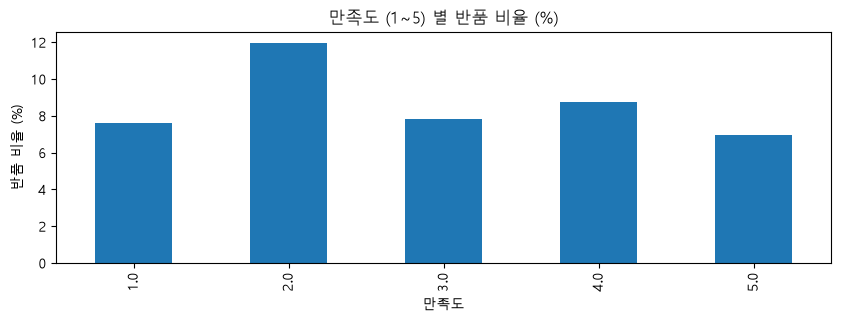

아니다.
상관계수 : -0.02


In [6]:
return_rate = (
    df.assign(is_returned=df["status"] == "반품")
      .groupby("satisfaction")["is_returned"]
      .mean() * 100
)

return_rate.plot(
    kind="bar",
    figsize=(10, 3)
)

plt.xlabel("만족도")
plt.ylabel("반품 비율 (%)")
plt.title("만족도 (1~5) 별 반품 비율 (%)")
plt.show()

print('아니다.')
print('상관계수 :', round(df['satisfaction'].corr(df['status'] == '반품'),2))


In [ ]:
display(df.groupby("category").agg(
    총매출_순위별=("total_sales", "sum"),
    건수=("category", "count"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean")
).sort_values(by='총매출_순위별', ascending=False))

print('카테고리 매출 1위의 이유는 건수, 평균단가로 보임.')
print('건수가 높을 수록 매출 순위가 높고, 평균 단가는 건수에 비해서 영향력은 적지만 기여도가 있어보임.')

,총매출_순위별,건수,평균단가,평균수량
category,,,,
가구,2.843337e+09,213,257322.909061,51.042254
식품,2.513274e+09,210,255232.928143,47.314286
전자제품,2.471628e+09,207,249651.606135,47.961353
도서,2.453240e+09,204,238500.636765,49.495098
의류,2.181904e+09,170,249447.162235,51.611765


카테고리 매출 1위의 이유는 건수, 평균단가로 보임.
건수가 높을 수록 매출 순위가 높고, 평균 단가는 건수에 비해서 영향력은 적지만 기여도가 있어보임.
